# Descriptive country profiles

Features are 2023 both-sex death ASDRs for organ and systemic groups. Equally weighted countries are transformed with log(1 + rate per 100,000), then each feature is standardized. This retains overall intensity while reducing skew; composition shares remove total intensity and introduce closure. Constant muscles are removed. Missing values are rejected, not imputed. Standardization also gives rare groups influence and log1p depends on the stated rate unit.

In [1]:
from pathlib import Path
import json
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "contracts/organs.json").exists())
sys.path.insert(0, str(root / "pipeline/src"))
import pandas as pd
from IPython.display import display, Markdown
from visceral_pipeline.analysis.data import CACHE, load_inputs, load_results
from visceral_pipeline.analysis import comparisons, sensitivity, clustering, plots
inputs, frames = load_inputs(), load_results()
meta = json.loads((CACHE / "metadata.json").read_text())
pd.set_option("display.max_rows", 65)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 140)


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\louis\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


In [2]:
rates = inputs['burden'].query("year==2023 and sex=='both' and measure=='deaths' and location!='WLD'").pivot(index='location',columns='organ',values='ageStdRate').sort_index().sort_index(axis=1)
features = clustering.feature_matrix(rates)
print(f'{features.shape[0]} countries; {features.shape[1]} nonconstant features; no imputation')
display(frames['cluster_diagnostics'])
print('Selection rule:',meta['clustering']['selection_rule'])
print('Selected k and stability criteria met:',clustering.choose_k(frames['cluster_diagnostics']))

185 countries; 30 nonconstant features; no imputation


,k,silhouette,ari_p05,ari_median,ari_p95,ari_mean,min_size,resamples
0,2,0.228863,0.873785,0.935838,0.978378,0.934267,83,100
1,3,0.191992,0.584667,0.856642,0.926117,0.817813,52,100
2,4,0.182983,0.570209,0.801667,0.924514,0.778951,34,100
3,5,0.180431,0.592370,0.777574,0.933597,0.772965,25,100
4,6,0.177502,0.519860,0.725739,0.868052,0.704639,14,100
5,7,0.147280,0.523787,0.656867,0.830600,0.667100,22,100
6,8,0.149202,0.557652,0.687086,0.819423,0.689341,1,100


Selection rule: Median bootstrap ARI >= 0.80, p05 >= 0.50, minimum size >= 5; best silhouette, within 0.02 prefer smaller k. If none qualify, use most stable k illustratively.
Selected k and stability criteria met: (2, True)


## Separation, stability and projection

The analyze command fits k=2…8 with 50 starts and seed 2026. For each k, 100 bootstrap resamples of countries refit the scaler and k-means (20 starts), predict all original countries and compute adjusted Rand index against the original fit. This measures algorithmic stability conditional on WHO point estimates, not source-estimate uncertainty. The selected k must meet median ARI ≥0.80, p05 ≥0.50 and minimum size ≥5; then the best silhouette wins, with a 0.02 tolerance preferring smaller k. PCA is for display only; all features are used for clustering.

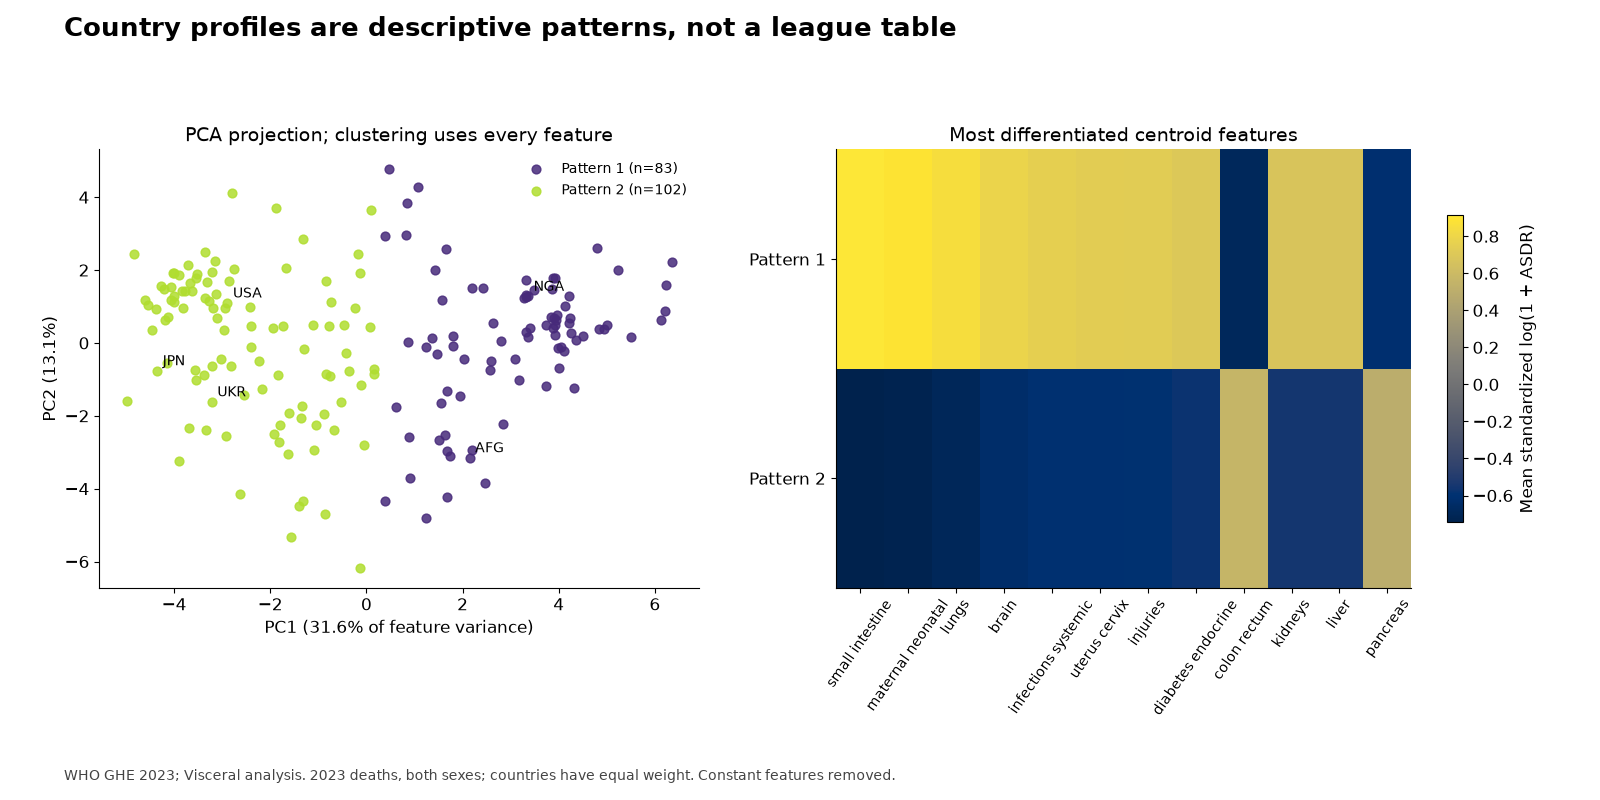

,cluster,n,higher_features,lower_features
0,1,83,"[small_intestine, maternal_neonatal, lungs]","[colon_rectum, pancreas, bladder]"
1,2,102,"[colon_rectum, pancreas, bladder]","[small_intestine, maternal_neonatal, lungs]"


PCA explained variance: [0.3164989617502411, 0.13095952320538717]


,cluster,organ,z,log_space_rate,median_rate,n
25,1,small_intestine,0.913536,3.630473e+01,49.496612,83
18,1,maternal_neonatal,0.889815,2.666393e+01,30.310305,83
17,1,lungs,0.850965,3.197046e+02,349.778909,83
3,1,brain,0.784582,3.235133e+02,355.468137,83
13,1,infections_systemic,0.754282,5.199752e+01,52.120776,83
29,1,uterus_cervix,0.738645,1.444095e+01,15.845868,83
14,1,injuries,0.729727,1.021002e+02,106.156064,83
7,1,diabetes_endocrine,0.700995,9.525003e+01,89.333606,83
15,1,kidneys,0.680289,6.985171e+01,73.268479,83
16,1,liver,0.677709,5.159918e+01,55.100319,83


In [3]:
plots.display_figure(plots.clustering(frames,meta))
display(pd.DataFrame(meta['clustering']['profiles']))
print('PCA explained variance:',meta['clustering']['pca_explained_variance'])
display(frames['cluster_centroids'].sort_values(['cluster','z'],ascending=[True,False]))

## Dependence on the analytical choice

Ward hierarchical clustering uses the same standardized log features and selected k. The alternative composition analysis uses shares, followed by feature standardization and k-means. Agreement is measured by ARI, which is invariant to cluster-label permutations. Modest agreement despite high within-method bootstrap stability argues against treating these patterns as natural country categories. Centroid descriptions are relative profiles, not judgments; members can differ substantially.

In [4]:
print('Ward agreement ARI:',meta['clustering']['hierarchical_ari'])
print('Composition agreement ARI:',meta['clustering']['composition_ari'])
display(pd.DataFrame(meta['clustering']['composition_k_diagnostics']))
display(frames['cluster_membership'].sort_values(['cluster','location']))

Ward agreement ARI: 0.39603236301321576
Composition agreement ARI: 0.39664963489094013


,k,silhouette
0,2,0.217266
1,3,0.171368
2,4,0.184238
3,5,0.188517
4,6,0.194120
5,7,0.155393
6,8,0.179381


,location,cluster,pc1,pc2,hierarchical_cluster,composition_cluster,name
0,AFG,1,2.144310,-3.152751,1,2,Afghanistan
1,AGO,1,4.011951,-0.694011,2,2,Angola
10,BDI,1,4.239326,0.674040,2,2,Burundi
12,BEN,1,3.861610,1.478817,2,2,Benin
13,BFA,1,3.325992,1.722586,2,2,Burkina Faso
...,...,...,...,...,...,...,...
172,UKR,2,-3.217435,-1.616786,1,2,Ukraine
173,URY,2,-2.803680,4.123987,1,1,Uruguay
174,USA,2,-2.892341,1.094661,1,1,United States of America
175,UZB,2,-1.314558,-4.334056,1,2,Uzbekistan
